In [8]:
print("test kernel")

test kernel


In [9]:
import sys
sys.path.insert(0, 'baseframework')
sys.path.insert(0, 'baseframework/data')
import numpy as np
import matplotlib.pyplot as plt
from baseframework import datahandler
from baseframework.offline_clustering.adjacency import adjacency_clustering
from baseframework.offline_clustering.density_peak_clustering import DensityPeakClustering

[[0.68479944 0.24851561]
 [0.3001912  0.76540947]
 [0.61570754 0.61467317]
 [0.70614274 0.32031927]
 [0.26602823 0.69761609]]
[0 1 2 0 1]


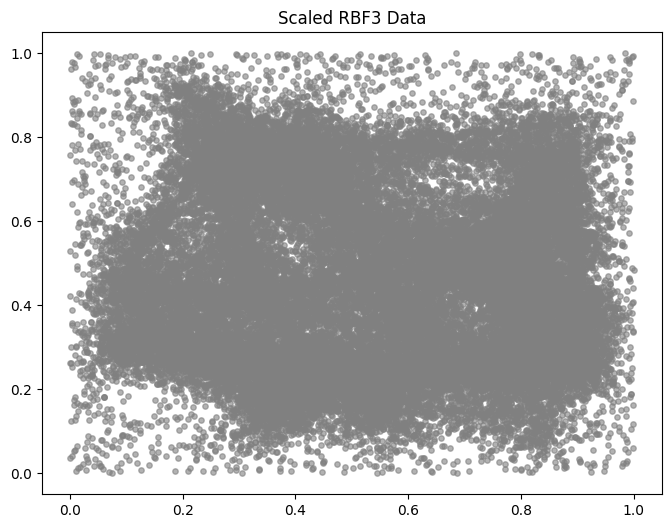

In [10]:
from IPython.display import clear_output
import time

# load the data with the handler
# This gives us the scaled features (X) and the ground truth labels (y)
X, y_true = datahandler.load_data("rbf3")
# understand the data
print(X[0:5])
print(y_true[0:5])

# plot
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=15, c='gray', alpha=0.6)
plt.title("Scaled RBF3 Data")
plt.show()

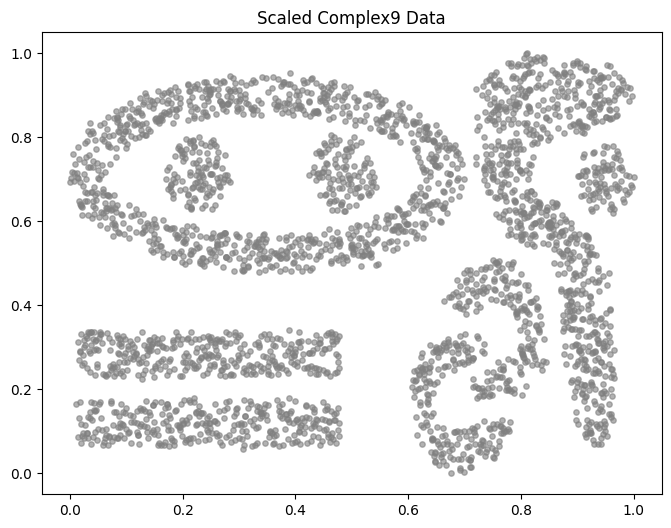

In [11]:
from sklearn.cluster import DBSCAN, KMeans

# load data
X_complex, y_complex = datahandler.load_data("complex9")
X_stream_dense, y_stream_dense = datahandler.load_data("stream_densired")

# plot
plt.figure(figsize=(8, 6))
plt.scatter(X_complex[:, 0], X_complex[:, 1], s=15, c='gray', alpha=0.6)
plt.title("Scaled Complex9 Data")
plt.show()


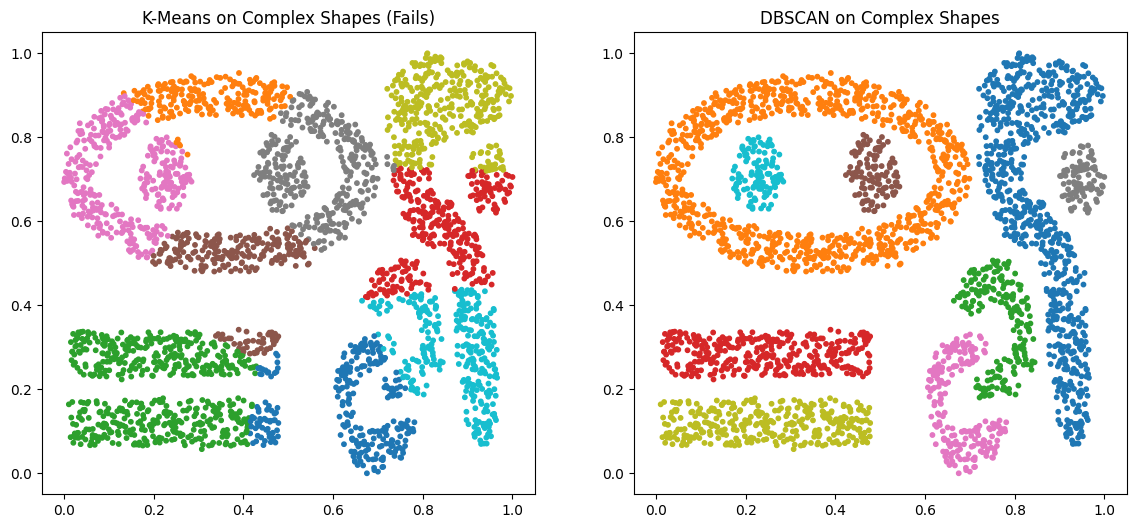

In [12]:
# run K-Means (guess 9 clusters)
kmeans = KMeans(n_clusters=9, random_state=42)
kmeans_labels = kmeans.fit_predict(X_complex)

# run DBSCAN
# play with eps and min_samples to try and perfectly isolate the 9 shapes!
dbscan = DBSCAN(eps=0.025, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_complex)

# plotting the comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X_complex[:, 0], X_complex[:, 1], c=kmeans_labels, cmap='tab10', s=10)
ax1.set_title("K-Means on Complex Shapes (Fails)")


colors = plt.cm.tab10(np.linspace(0, 1, 10))
ax2.scatter(X_complex[:, 0], X_complex[:, 1], c=dbscan_labels, cmap='tab10', s=10)
ax2.set_title("DBSCAN on Complex Shapes")

plt.show()

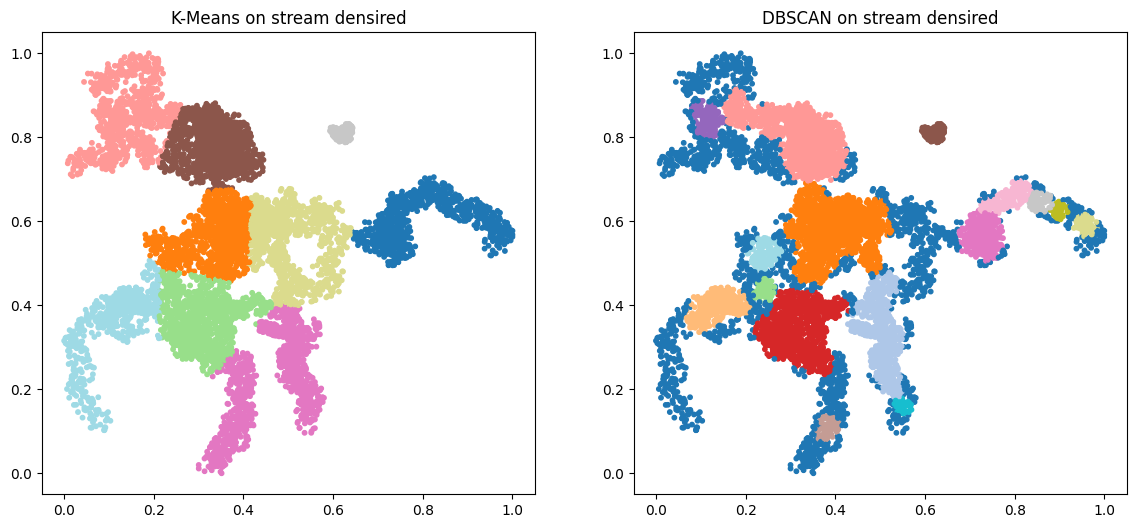

In [13]:
# run K-Means
kmeans = KMeans(n_clusters=9, random_state=42)
kmeans_labels = kmeans.fit_predict(X_stream_dense)

# run DBSCAN

dbscan = DBSCAN(eps=0.0199, min_samples=40)
dbscan_labels = dbscan.fit_predict(X_stream_dense)

# plotting the comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.scatter(X_stream_dense[:, 0], X_stream_dense[:, 1], c=kmeans_labels, cmap='tab20', s=10)
ax1.set_title("K-Means on stream densired")


colors = plt.cm.tab10(np.linspace(0, 1, 10))
ax2.scatter(X_stream_dense[:, 0], X_stream_dense[:, 1], c=dbscan_labels, cmap='tab20', s=10)
ax2.set_title("DBSCAN on stream densired")

plt.show()

In [14]:
# TODO play around and test with DenStream


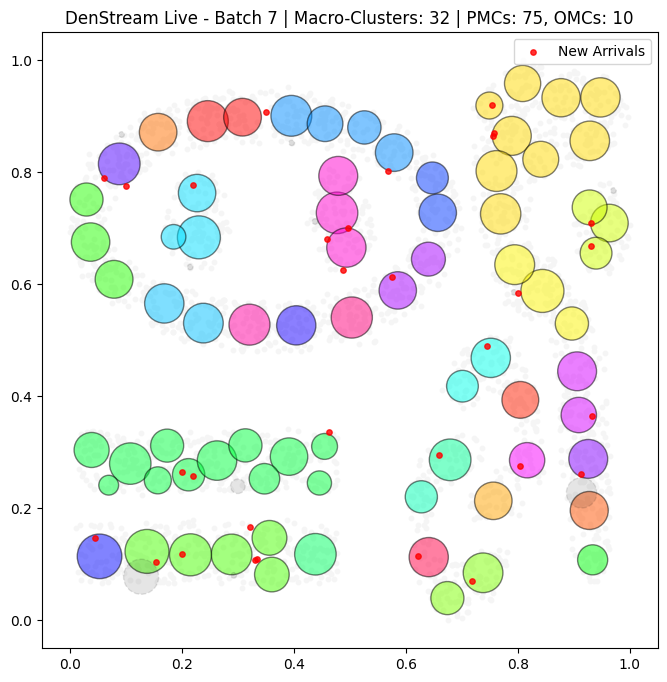

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import clear_output
import time
from baseframework import datahandler
from src.denstream import DenStream
from src.micro_clusters import MicroClusterType

RANDOM_SEED = 12

# 1. Load Data: (stream_densired, coplex9, rbf3, har)
X, _ = datahandler.load_data("complex9")


# 2. initialize DenStream
# NOTE: Role of each parameter
# - epsilon: sets the strict maximum radius, a micro-cluster is allowed to grow
#           effect -> very small epsilon means micro-clusters are tiny, and it will take a large number of      #           microclusters or 'bubbles' to cover a shape. a larger epsilon means fewer but larger 'bubbles'

# - mu: this is the minimum weight a PMC must acheive to be considered dense during the offline phase
#           effect -> if mu is very high, a bubble must absorb many points to become dense. if it doesn't reach   #           mu, the offline DBSCAN will not use it to connect to other bubbles

# - beta: this is the threshold for an OMC to be promoted to a PMC (beta * mu)
#           effect -> lower beta means a brand new OMC might only need one more point to be promoted

# - lambda: this is the forgetting rate -> how fast the algorithm forgets old data

denstream = DenStream(epsilon=0.04, mu=5.0, beta=0.45, lambda_decay=0.000001)

batch_size = 500
num_batches = len(X)
rng = np.random.default_rng(RANDOM_SEED)
X = rng.permutation(X)


def get_distinct_color(cluster_id):
    if cluster_id == -1:
        return 'black' # Noise

    # The golden angle in degrees
    golden_angle = 137.508

    # Calculate a unique hue [0, 1] for this cluster ID
    hue = (cluster_id * golden_angle) % 360 / 360.0

    # Fetch the color from the HSV colormap
    return plt.cm.hsv(hue)

# 3. simulate animation of data stream
for i in range(num_batches + 1):
    start_idx = i * batch_size
    end_idx = min((i + 1) * batch_size, len(X))
    batch = X[start_idx:end_idx]

    if len(batch) == 0:
        break

    #ONLINE PHASE
    # timestamps = np.arange(start_idx, end_idx)
    timestamps = np.ones(end_idx - start_idx, dtype=int)
    denstream.learn(batch, timestamps)

    # OFFLINE PHASE
    # 1. Get the macro-cluster labels {mc_id: cluster_id}
    clustering_dict = denstream.predict()

    # 2. Get the actual micro-cluster objects {mc_id: MicroCluster} so we can draw them
    summaries = denstream.online_phase.get_summary()

    # VISUALIZATION
    clear_output(wait=True)
    fig, ax = plt.subplots(figsize=(10, 8))

    # plot the entire dataset faintly in the background
    ax.scatter(X[:, 0], X[:, 1], c='whitesmoke', s=10, zorder=0)

    # Plot the current batch arriving as bright red dots
    ax.scatter(batch[:, 0], batch[:, 1], c='red', s=15, alpha=0.8, label="New Arrivals", zorder=2)

    # draw the micro clusters
    for mc_id, mc in summaries.items():
        center = mc.get_center()
        radius = mc.get_radius()

        # Get the macro-cluster label (-1 if it's noise or an OMC)
        cluster_id = clustering_dict.get(mc_id, -1)

        if cluster_id == -1:
            # this is an OMC or a PMC that didn't have enough weight
            color = 'black'
            alpha = 0.1
            edge_style = '--' # Dashed borders for noise mc
        else:
            # this is a valid, clustered PMC
            color = get_distinct_color(cluster_id)
            alpha = 0.5
            edge_style = '-'

        # Draw the bubble! (We enforce a minimum visual radius of 0.005 so brand new 1-point OMCs are visible)
        circle = Circle(center, max(radius, 0.005),
                        linewidth=1, edgecolor='black', linestyle=edge_style,
                        facecolor=color, alpha=alpha, zorder=1)
        ax.add_patch(circle)

    # Calculate stats for the title
    unique_clusters = set(val for val in clustering_dict.values() if val != -1)
    num_clusters = len(unique_clusters)
    num_pmcs = sum(1 for mc in summaries.values() if mc.mc_type.value == "potential")
    num_omcs = sum(1 for mc in summaries.values() if mc.mc_type.value == "outlier")

    ax.set_title(f"DenStream Live - Batch {i+1} | Macro-Clusters: {num_clusters} | PMCs: {num_pmcs}, OMCs: {num_omcs}")
    ax.set_aspect('equal', 'box')
    ax.legend(loc="upper right")

    plt.show()

    time.sleep(0.5)

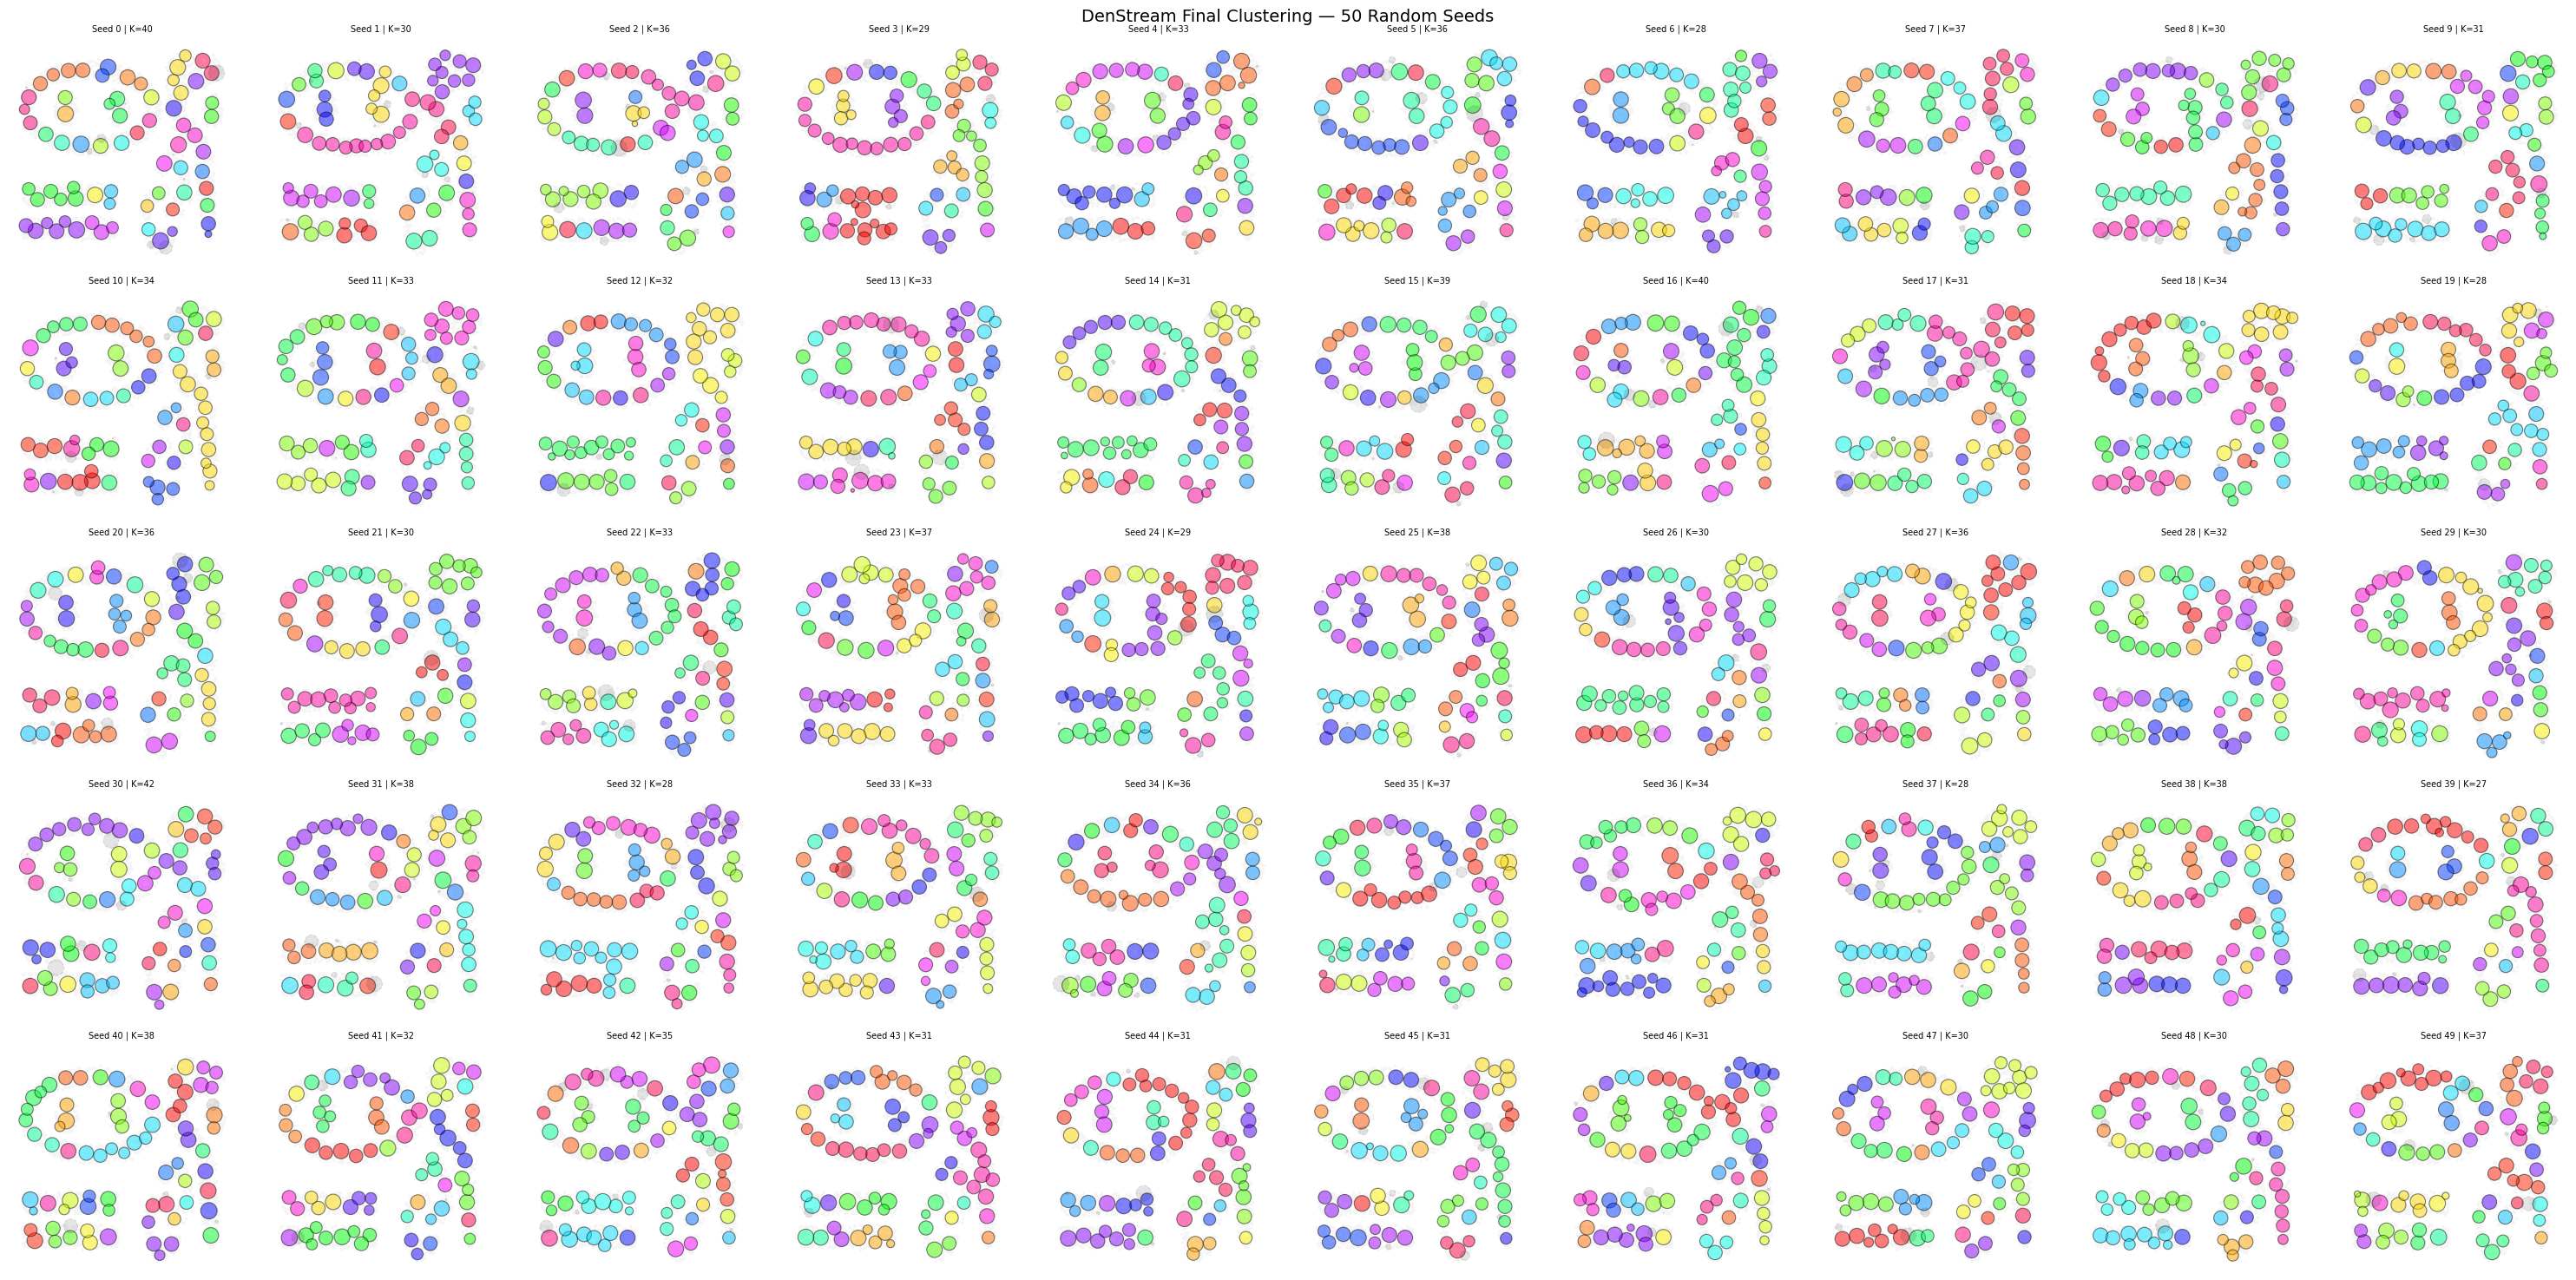

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from baseframework import datahandler
from src.denstream import DenStream

X, _ = datahandler.load_data("complex9")

batch_size = 50

def get_distinct_color(cluster_id):
    if cluster_id == -1:
        return 'black'
    hue = (cluster_id * 137.508) % 360 / 360.0
    return plt.cm.hsv(hue)

def run_denstream(X_shuffled):
    denstream = DenStream(epsilon=0.04, mu=5.0, beta=0.45, lambda_decay=0.000001)
    num_batches = len(X_shuffled) // batch_size
    for i in range(num_batches + 1):
        start_idx = i * batch_size
        end_idx = min((i + 1) * batch_size, len(X_shuffled))
        batch = X_shuffled[start_idx:end_idx]
        if len(batch) == 0:
            break
        denstream.learn(batch, np.zeros(len(batch), dtype=int))
    clustering_dict = denstream.predict()
    summaries = denstream.online_phase.get_summary()
    return dict(clustering_dict), dict(summaries)

# Run 50 seeds and collect final clustering results
num_seeds = 50
final_results = []
for seed in range(num_seeds):
    rng = np.random.default_rng(seed)
    X_shuffled = rng.permutation(X)
    clustering_dict, summaries = run_denstream(X_shuffled)
    final_results.append({'seed': seed, 'clustering_dict': clustering_dict, 'summaries': summaries})

# Plot all 50 final results in a 10x5 grid
cols = 10
rows = (num_seeds + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 3, rows * 3))
axes = axes.flatten()

for idx, res in enumerate(final_results):
    ax = axes[idx]
    clustering_dict = res['clustering_dict']
    summaries = res['summaries']

    ax.scatter(X[:, 0], X[:, 1], c='whitesmoke', s=2, zorder=0)

    for mc_id, mc in summaries.items():
        center = mc.get_center()
        radius = mc.get_radius()
        cluster_id = clustering_dict.get(mc_id, -1)
        if cluster_id == -1:
            color, alpha, edge_style = 'black', 0.1, '--'
        else:
            color, alpha, edge_style = get_distinct_color(cluster_id), 0.5, '-'
        circle = Circle(center, radius,
                        linewidth=0.8, edgecolor='black', linestyle=edge_style,
                        facecolor=color, alpha=alpha, zorder=1)
        ax.add_patch(circle)

    unique_clusters = set(v for v in clustering_dict.values() if v != -1)
    ax.set_title(f"Seed {res['seed']} | K={len(unique_clusters)}", fontsize=7)
    ax.set_aspect('equal', 'box')
    ax.axis('off')

for idx in range(num_seeds, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("DenStream Final Clustering — 50 Random Seeds", fontsize=14)
plt.tight_layout()
plt.show()
